In [34]:
# import dataset

import kagglehub

# Download latest version
path = kagglehub.dataset_download("slavkoprytula/aquarium-data-cots")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'aquarium-data-cots' dataset.
Path to dataset files: /kaggle/input/aquarium-data-cots


In [35]:
# edit yaml to point to the right folders and save it in a writable location

from pathlib import Path

dataset = Path(path) / "aquarium_pretrain"
# Save the YAML file in the writable /content directory instead of the read-only dataset folder
yaml_path = Path("/content/data.yaml")

yaml_path.write_text(f"""path: {dataset}
train: train/images
val: valid/images
test: test/images

nc: 7
names: ['fish', 'jellyfish', 'penguin', 'puffin', 'shark', 'starfish', 'stingray']
""")

print(f"Successfully wrote dataset configuration to writable path: {yaml_path}")

Successfully wrote dataset configuration to writable path: /content/data.yaml


In [36]:
# train model

!pip install -q ultralytics

from ultralytics import YOLO

MODEL = "yolo26m"

model = YOLO(f"{MODEL}.pt")
model.train(
    data=str(yaml_path),
    epochs=100,
    imgsz=640,
    batch=8,
    device="0",
    project="/content/drive/MyDrive/aquarium_runs",
    name=f"{MODEL}"
)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26m, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto,

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7c74ad5cd320>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
  


image 1/1 /kaggle/input/aquarium-data-cots/aquarium_pretrain/test/images/IMG_2473_jpeg_jpg.rf.6284677f9c781b0cfeec54981a17d573.jpg: 640x480 4 jellyfishs, 44.7ms
Speed: 1.9ms preprocess, 44.7ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 480)


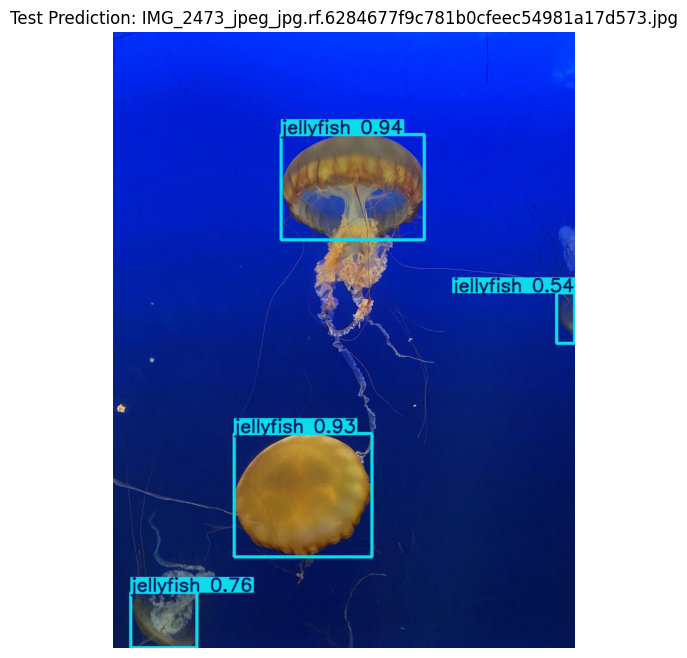


image 1/1 /kaggle/input/aquarium-data-cots/aquarium_pretrain/test/images/IMG_3134_jpeg_jpg.rf.50750ca778773042a3c46a1d3e480132.jpg: 640x480 2 puffins, 38.1ms
Speed: 2.8ms preprocess, 38.1ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 480)


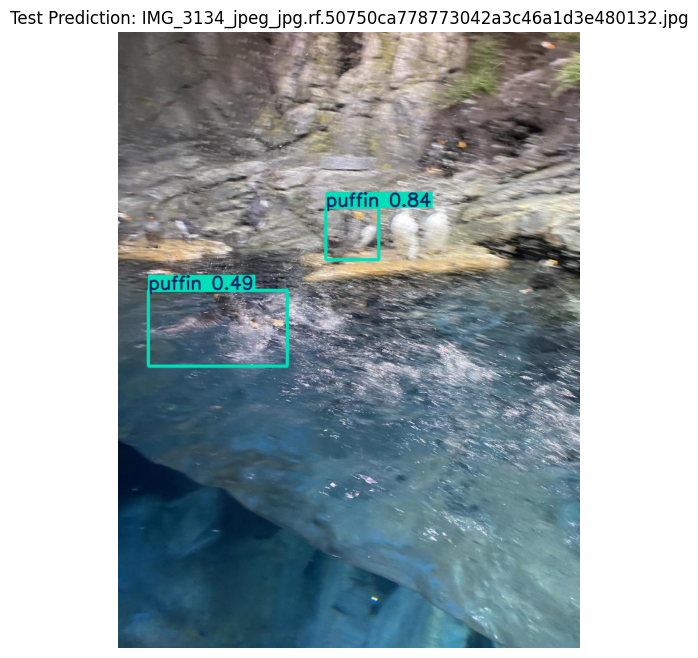


image 1/1 /kaggle/input/aquarium-data-cots/aquarium_pretrain/test/images/IMG_2387_jpeg_jpg.rf.09b38bacfab0922a3a6b66480f01b719.jpg: 640x480 1 starfish, 38.1ms
Speed: 3.0ms preprocess, 38.1ms inference, 2.0ms postprocess per image at shape (1, 3, 640, 480)


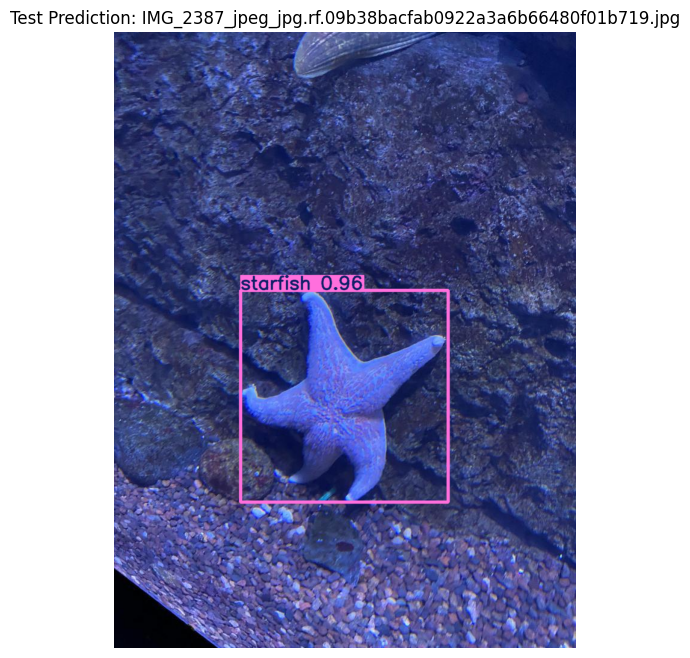


image 1/1 /kaggle/input/aquarium-data-cots/aquarium_pretrain/test/images/IMG_2446_jpeg_jpg.rf.06ee05e92df8e3c33073147d8f595211.jpg: 640x480 7 fishs, 4 sharks, 38.0ms
Speed: 2.6ms preprocess, 38.0ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 480)


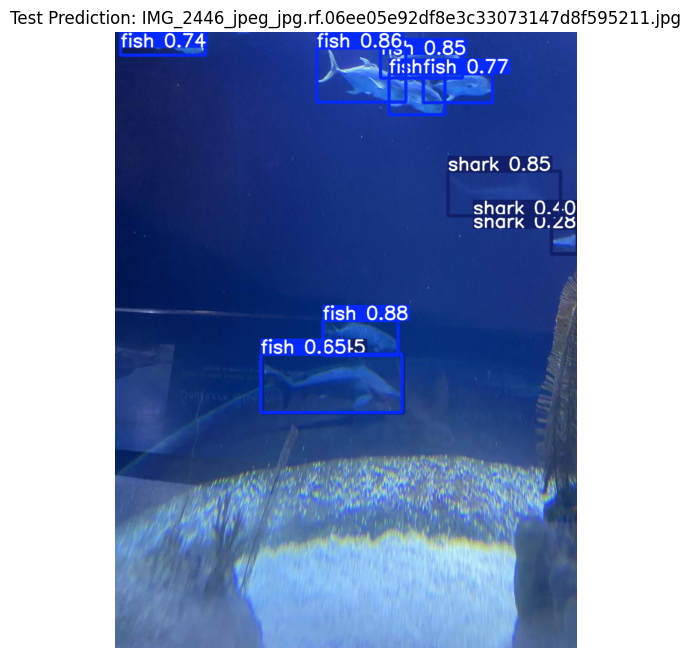


image 1/1 /kaggle/input/aquarium-data-cots/aquarium_pretrain/test/images/IMG_2477_jpeg_jpg.rf.7b2692f142d53c16ad477065f1f8ae6d.jpg: 640x480 7 jellyfishs, 38.5ms
Speed: 4.2ms preprocess, 38.5ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 480)


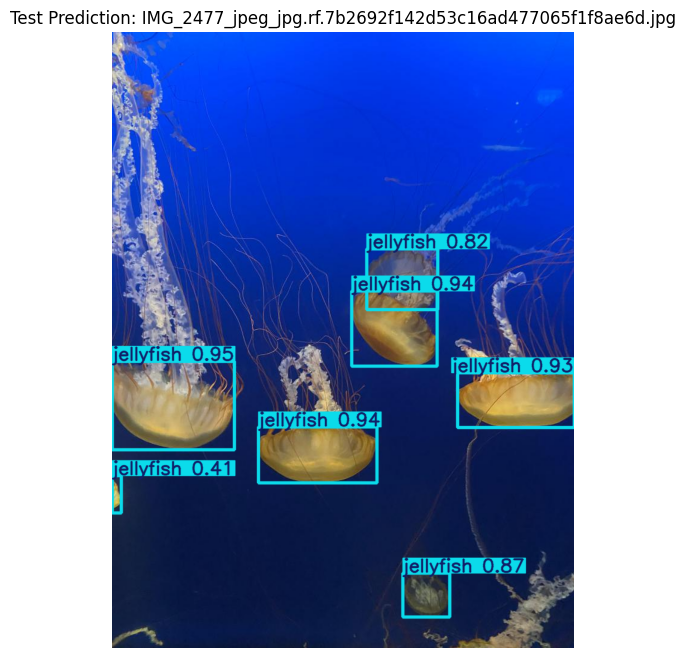


image 1/1 /kaggle/input/aquarium-data-cots/aquarium_pretrain/test/images/IMG_8331_jpg.rf.ec024bdf1e9de02b020b5e6505c1c58b.jpg: 480x640 2 fishs, 52.0ms
Speed: 3.8ms preprocess, 52.0ms inference, 1.8ms postprocess per image at shape (1, 3, 480, 640)


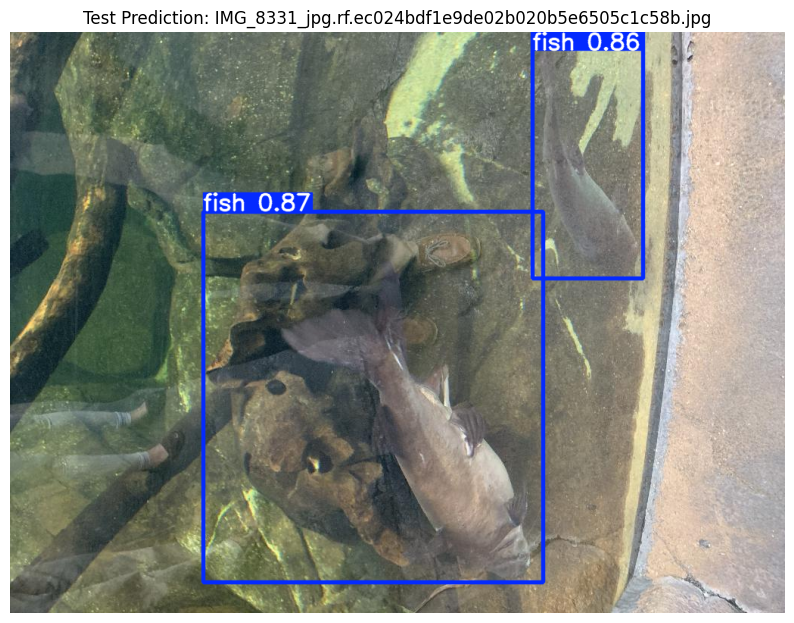


image 1/1 /kaggle/input/aquarium-data-cots/aquarium_pretrain/test/images/IMG_2395_jpeg_jpg.rf.9f1503ad3b7a7c7938daed057cc4e9bc.jpg: 640x480 6 fishs, 46.2ms
Speed: 2.5ms preprocess, 46.2ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 480)


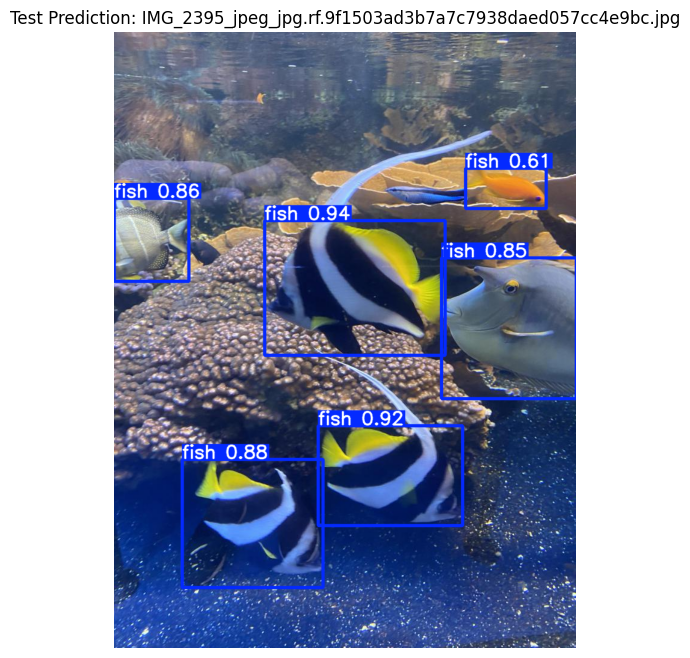


image 1/1 /kaggle/input/aquarium-data-cots/aquarium_pretrain/test/images/IMG_2630_jpeg_jpg.rf.310f0c986a72be46b80ce31c2d00e46d.jpg: 640x480 3 fishs, 1 stingray, 44.9ms
Speed: 2.7ms preprocess, 44.9ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 480)


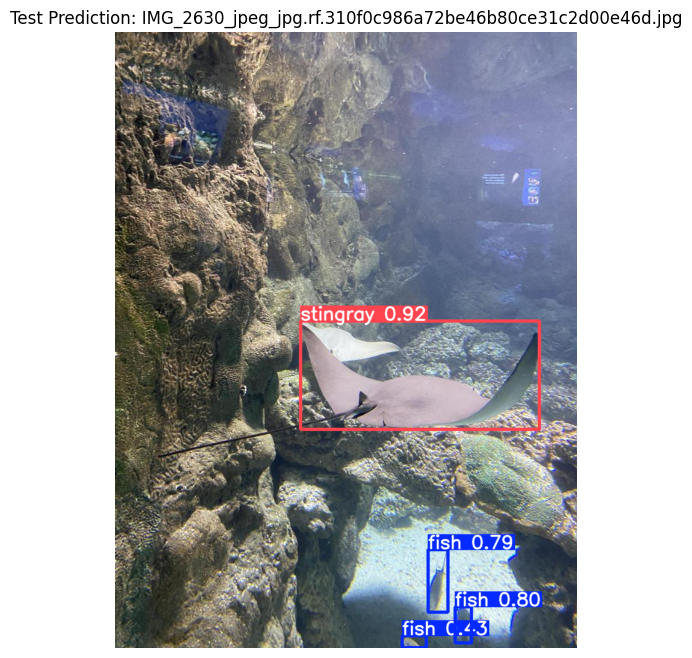


image 1/1 /kaggle/input/aquarium-data-cots/aquarium_pretrain/test/images/IMG_8513_MOV-0_jpg.rf.2a2f77e3f73630b60aaf6ad3ca4ed130.jpg: 640x384 5 fishs, 48.0ms
Speed: 2.2ms preprocess, 48.0ms inference, 2.8ms postprocess per image at shape (1, 3, 640, 384)


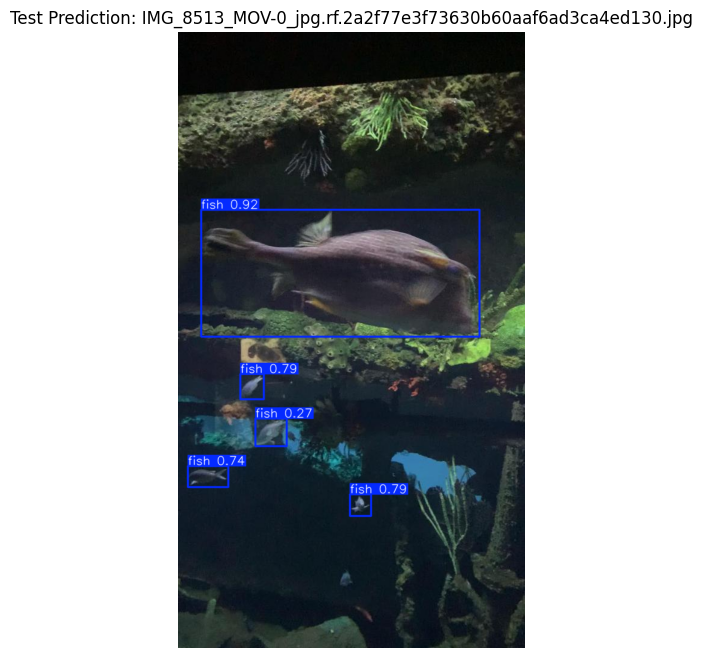


image 1/1 /kaggle/input/aquarium-data-cots/aquarium_pretrain/test/images/IMG_2588_jpeg_jpg.rf.cb9cea8f05891cfd55a3e93f2908201f.jpg: 640x480 3 stingrays, 45.9ms
Speed: 2.7ms preprocess, 45.9ms inference, 2.0ms postprocess per image at shape (1, 3, 640, 480)


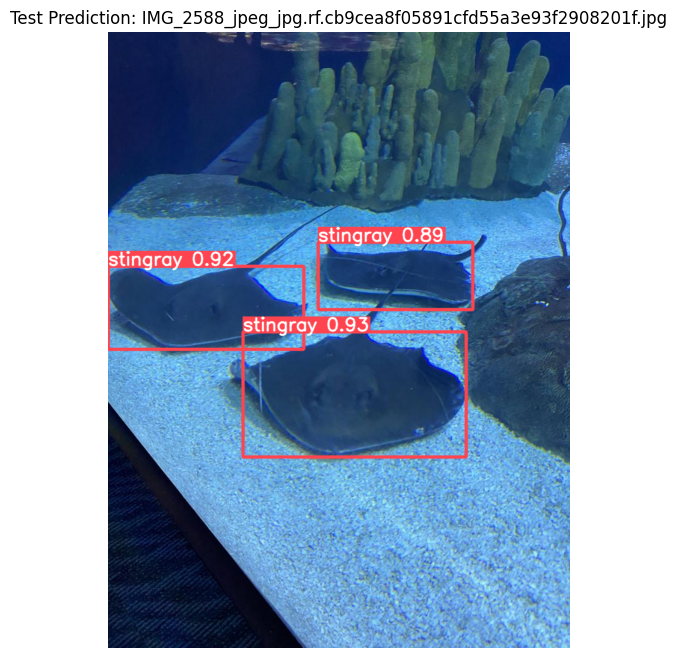

In [45]:
# testing the model
from ultralytics import YOLO
import matplotlib.pyplot as plt
from pathlib import Path
import cv2

MODEL = "yolo26m"

model_path = Path(f"/content/drive/MyDrive/aquarium_runs/{MODEL}/weights/best.pt")
if not model_path.exists():
    print(f"Could not find trained weights")
else:
    # load the trained model
    model = YOLO(model_path)

    # get test images
    test_images_dir = Path(path) / "aquarium_pretrain/test/images"
    test_images = list(test_images_dir.glob("*.jpg"))

    if not test_images:
        print("Test images not found")
    else:
        for img_path in test_images[:10]:
            results = model(img_path)

            for r in results:
                # plot bounding boxes with labels
                im_bgr = r.plot()
                # convert to RGB for plotting
                im_rgb = cv2.cvtColor(im_bgr, cv2.COLOR_BGR2RGB)

                plt.figure(figsize=(10, 8))
                plt.imshow(im_rgb)
                plt.axis("off")
                plt.title(f"Test Prediction: {img_path.name}")
                plt.show()

In [46]:
# evaluating the trained model on the test dataset
from ultralytics import YOLO
from pathlib import Path

model_path = Path(f"/content/drive/MyDrive/aquarium_runs/{MODEL}/weights/best.pt")

if not model_path.exists():
    print(f"Could not find trained weights at: {model_path}")
else:
    # Load the trained model
    model = YOLO(model_path)

    # Run validation on the test split using the configured data.yaml
    # Setting split='test' tells the model to evaluate on the test partition defined in data.yaml
    metrics = model.val(data=str(yaml_path), split='test')

    # Display the specific metrics requested
    print("\n=== Object Detection Metrics on Test Dataset ===")
    print(f"Precision (all classes):  {metrics.results_dict['metrics/precision(B)']:.4f}")
    print(f"Recall (all classes):     {metrics.results_dict['metrics/recall(B)']:.4f}")
    print(f"mAP@0.5:                  {metrics.results_dict['metrics/mAP50(B)']:.4f}")
    print(f"mAP@0.5:0.95:             {metrics.results_dict['metrics/mAP50-95(B)']:.4f}")


Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26m summary (fused): 130 layers, 20,354,849 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 195.2±98.3 MB/s, size: 86.9 KB)
val: Scanning /kaggle/input/aquarium-data-cots/aquarium_pretrain/test/labels... 63 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 63/63 588.0it/s 0.1s
WARNING ⚠️ val: Cache directory /kaggle/input/aquarium-data-cots/aquarium_pretrain/test is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.0it/s 3.9s
                   all         63        584      0.848      0.808      0.849      0.527
                  fish         30        249      0.802      0.811      0.843      0.516
             jellyfish         11        154       0.83       0.89      0.882      0.556
               penguin          7         82      0.862      0.793      0.824  